In [1]:
# %matplotlib ipympl
from erna_utils.database import walk_dir, Database

from erna_utils.file import plot_od, ShotFile, ShotFileMultiImg, generate_xys, max_od, ShotFileTOF
from datetime import datetime, timedelta
from tqdm import tqdm
import numpy as np
import matplotlib as mpl
# mpl.use('tkagg')
import matplotlib.pyplot as plt
import re
from scipy.optimize import curve_fit
from multiprocess import Pool

from lmfit import Model
from matplotlib.offsetbox import AnchoredText
from scipy import ndimage
import pandas as pd

plt.rc('font', size=10)
plt.rc('figure', figsize=(6.4, 4.8))


erna_db = Database()
ShotRecord = erna_db.Shot

Database loaded. Number of record: 165120.


In [2]:
from erna_utils.feature_detection import vector_quantize, detect_interest_class, detect_interest_region

## PCA Helper functions

In [3]:
def norm(img, mean, var):
    return (img - mean) / var

def unnorm(img, mean, var):
    return img * var + mean

def minimize_residue(img_to_fit, basis):
    from sklearn.linear_model import LinearRegression
    
    y = img_to_fit.flatten()
    X = basis.reshape((basis.shape[0], -1)).transpose()
    
    reg = LinearRegression(fit_intercept=False)
    reg.fit(X, y)
    
    print(f"r^2: {reg.score(X, y):.4f}")
    
    return reg.predict(X).reshape(img_to_fit.shape)

def minimize_residue_sgd(img_to_fit, basis):
    from sklearn.linear_model import SGDRegressor
    
    y = img_to_fit.flatten()
    X = basis.reshape((basis.shape[0], -1)).transpose()
    
    reg = SGDRegressor(fit_intercept=False)
    reg.fit(X, y)
    
    print(f"r^2: {reg.score(X, y):.4f}")
    
    return reg.predict(X).reshape(img_to_fit.shape)

def recon(img, pca_basis, n_basis):
    decom = np.array([ np.sum(img * b) for b in pca_basis[:n_basis] ])
    return np.sum([decom[i] * pca_basis[i] for i in range(len(decom))], axis=0)

## Image centering

In [4]:
from scipy.ndimage import gaussian_filter

def center_images(imgs, crop_radius=70):
    max_x = 0
    max_y = 0

    min_x = imgs[0].shape[1]
    min_y = imgs[0].shape[0]

    for img in tqdm(imgs):
        od = gaussian_filter(img, sigma=5)

        quantized = vector_quantize(od, n_quantize_level=2, block_size=4)

        region_of_interest = detect_interest_region(quantized, 2)

        min_x = min(min_x, np.min(region_of_interest[:,1])*4)
        max_x = max(max_x, np.max(region_of_interest[:,1])*4)

        min_y = min(min_y, np.min(region_of_interest[:,0])*4)
        max_y = max(max_y, np.max(region_of_interest[:,0])*4)

    min_x -= crop_radius*2
    min_y -= crop_radius*2

    max_x += crop_radius*2
    max_y += crop_radius*2
    
    ret = np.zeros((len(imgs), crop_radius*2, crop_radius*2))
    
    for i, img in enumerate(tqdm(imgs)):
        od = img[min_y:max_y, min_x:max_x]

        od_sum_x = np.sum(od, axis=1)
        com_x = int(np.sum(np.arange(od.shape[0]) * od_sum_x) / np.sum(od_sum_x))

        od_sum_y = np.sum(od, axis=0)
        com_y = int(np.sum(np.arange(od.shape[1]) * od_sum_y) / np.sum(od_sum_y))
        
        ret[i] = od[com_x - crop_radius:com_x + crop_radius, com_y - crop_radius:com_y + crop_radius]

    return ret

In [5]:
import cv2

def rotate_image(image, angle, center=None):
  image_center = tuple(np.array(image.shape[1::-1]) / 2) if not center else center
  rot_mat = cv2.getRotationMatrix2D(image_center, angle/np.pi*180, 1.0)
  result = cv2.warpAffine(image, rot_mat, image.shape[1::-1], flags=cv2.INTER_NEAREST)
  return result

In [6]:
from datetime import datetime
import os

def simple_select_shots(y, m, d, script, shot_nums):
    date = datetime(y, m, d).timestamp() 
    shots_rec = ShotRecord.select().where(
        (ShotRecord.script == script) \
        & ((ShotRecord.shot_num.in_(shot_nums))) \
        & (ShotRecord.shot_time.between(date, date + 24*3600))
    )
    
    print("Total shots: ", shots_rec.count())

    return shots_rec
    

In [7]:
def readMultiImg(program,yy,mm,dd,shotnums,plotFirst=True):
    shots_rec = simple_select_shots(yy, mm, dd, program, shotnums)
    shots = [ShotFileMultiImg(s.shot_path, "cam6") for s in tqdm(shots_rec) if os.path.isfile(s.shot_path)]

    if plotFirst:
        if shots[0].BEC_SEQ_RUN_UNTIL == -1:
            od0 = shots[0].od(0); od1 = shots[0].od(1)
            fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(10,8))
            ax1.imshow(od0); ax2.imshow(od1)
            plt.show()
        else:
            print("BEC SEQ RUN UNTIL", shots[0].BEC_SEQ_RUN_UNTIL)
            od1 = shots[0].od(1)
            plt.imshow(od1)
            plt.show()
            
    return shots

def readImgTOF(program,yy,mm,dd,shotnums,cam):
    shots_rec = simple_select_shots(yy, mm, dd, program, shotnums)
    shots = [ShotFileTOF(s.shot_path, cam) for s in tqdm(shots_rec) if os.path.isfile(s.shot_path)]
    
    if shots[0].BEC_SEQ_RUN_UNTIL == -1:
        od = shots[0].od
        plt.imshow(od)
        plt.show()
         
    return shots
    
# shots_rec = simple_select_shots(2026, 5, 7, "bec_box_vortex_disc_imprint_multi", [1])
# shots = [ShotFileMultiImg(s.shot_path, "cam6") for s in tqdm(shots_rec) if os.path.isfile(s.shot_path)]

# if shots[0].BEC_SEQ_RUN_UNTIL == -1:
#     od0 = shots[0].od(0); od1 = shots[0].od(1)
#     fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(10,8))
#     ax1.imshow(od0); ax2.imshow(od1)
#     plt.show()
# else:
#     print("BEC SEQ RUN UNTIL", shots[0].BEC_SEQ_RUN_UNTIL)
#     od1 = shots[0].od(1)
#     plt.imshow(od1)
#     plt.show()

## example

Total shots:  17


100%|██████████| 17/17 [00:00<00:00, 59.53it/s]


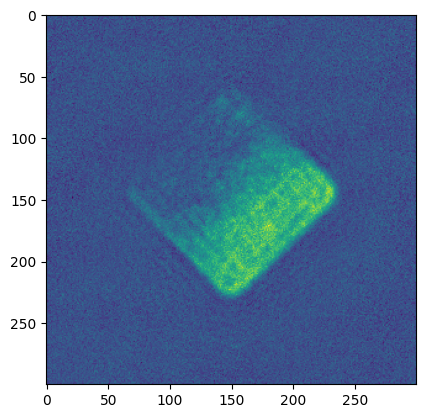

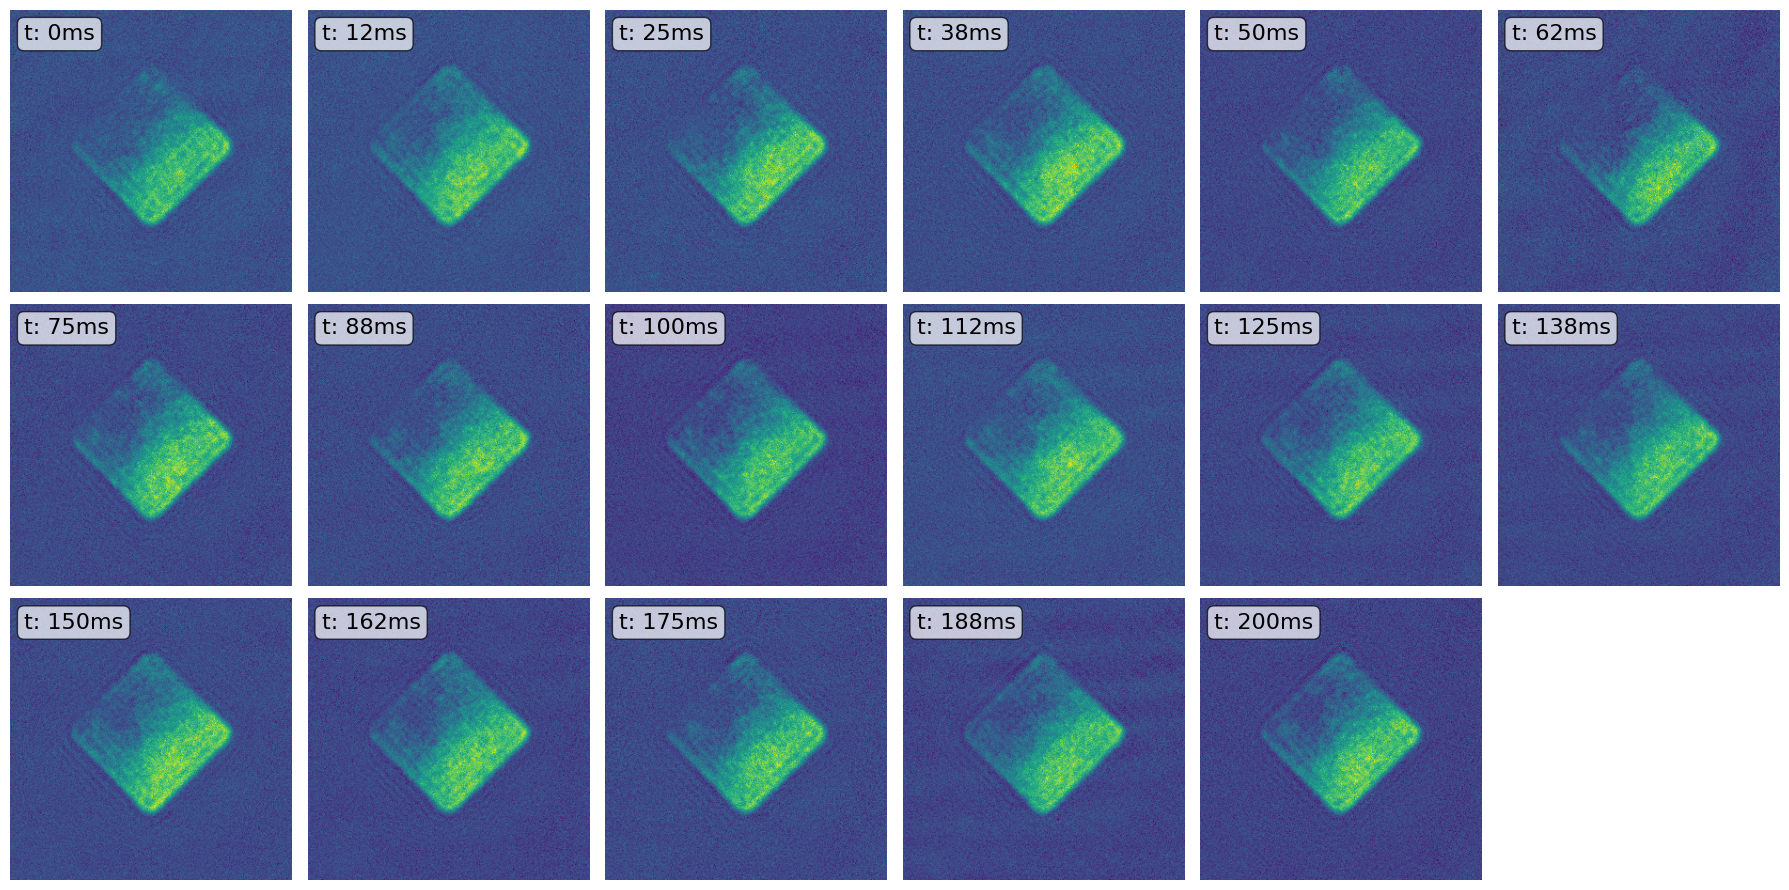

In [13]:
program = "bec_box_vortex_disc_imprint_slosh_multi_qi2"; yy=2026; mm=7; dd=10

shotnums = [12] # also 8,9,10,11,16
shots = readImgTOF(program,yy,mm,dd,shotnums,"cam6")

fig,ax = plt.subplots(3,6,figsize=(18,9)); ax = ax.flatten()
for i in range(len(shots)):
    ax[i].imshow(shots[i].od)
    ax[i].text(
    0.05, 0.95,
    f"t: {shots[i].EVOLVE_TIME*1e3:.0f}ms",
    transform=ax[i].transAxes,
    fontsize=16,
    verticalalignment='top',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.7)
    )


for i in range(len(ax)):
    ax[i].axis('off')

plt.tight_layout()
plt.show()
plt.show()

## example

In [8]:
program = "bec_box2"; yy=2026; mm=7; dd=17

shotnums = [23] # also 8,9,10,11,16
shots = readImg(program,yy,mm,dd,shotnums,"cam6")

fig,ax = plt.subplots(3,6,figsize=(18,9)); ax = ax.flatten()
for i in range(len(shots)):
    ax[i].imshow(shots[i].od)
    ax[i].text(
    0.05, 0.95,
    f"t: {shots[i].EVOLVE_TIME*1e3:.0f}ms",
    transform=ax[i].transAxes,
    fontsize=16,
    verticalalignment='top',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.7)
    )


for i in range(len(ax)):
    ax[i].axis('off')

plt.tight_layout()
plt.show()
plt.show()

Total shots:  5


100%|██████████| 5/5 [00:00<00:00, 61.67it/s]


KeyError: "Unable to synchronously open object (object 'PTAI' doesn't exist)"

In [10]:
shots_rec = simple_select_shots(2026, 7, 17, "bec_box2", [22])

shots = [ShotFileMultiImg(s.shot_path, "cam6") for s in tqdm(shots_rec) if os.path.isfile(s.shot_path)]

shots[0].BOX_OPACITY

Total shots:  85


100%|██████████| 85/85 [00:01<00:00, 70.51it/s]


np.int32(1)

In [15]:
evolve_time = [s.BEC_TIME_SEQ[6] for s in shots]
print(evolve_time)

[np.float64(0.0), np.float64(0.05), np.float64(0.1), np.float64(0.15000000000000002), np.float64(0.2), np.float64(0.25), np.float64(0.30000000000000004), np.float64(0.35000000000000003), np.float64(0.4), np.float64(0.45), np.float64(0.5), np.float64(0.55), np.float64(0.6000000000000001), np.float64(0.65), np.float64(0.7000000000000001), np.float64(0.75), np.float64(0.8), np.float64(0.0), np.float64(0.05), np.float64(0.1), np.float64(0.15000000000000002), np.float64(0.2), np.float64(0.25), np.float64(0.30000000000000004), np.float64(0.35000000000000003), np.float64(0.4), np.float64(0.45), np.float64(0.5), np.float64(0.55), np.float64(0.6000000000000001), np.float64(0.65), np.float64(0.7000000000000001), np.float64(0.8), np.float64(0.0), np.float64(0.05), np.float64(0.1), np.float64(0.15000000000000002), np.float64(0.2), np.float64(0.25), np.float64(0.30000000000000004), np.float64(0.35000000000000003), np.float64(0.4), np.float64(0.45), np.float64(0.5), np.float64(0.55), np.float64(0.60